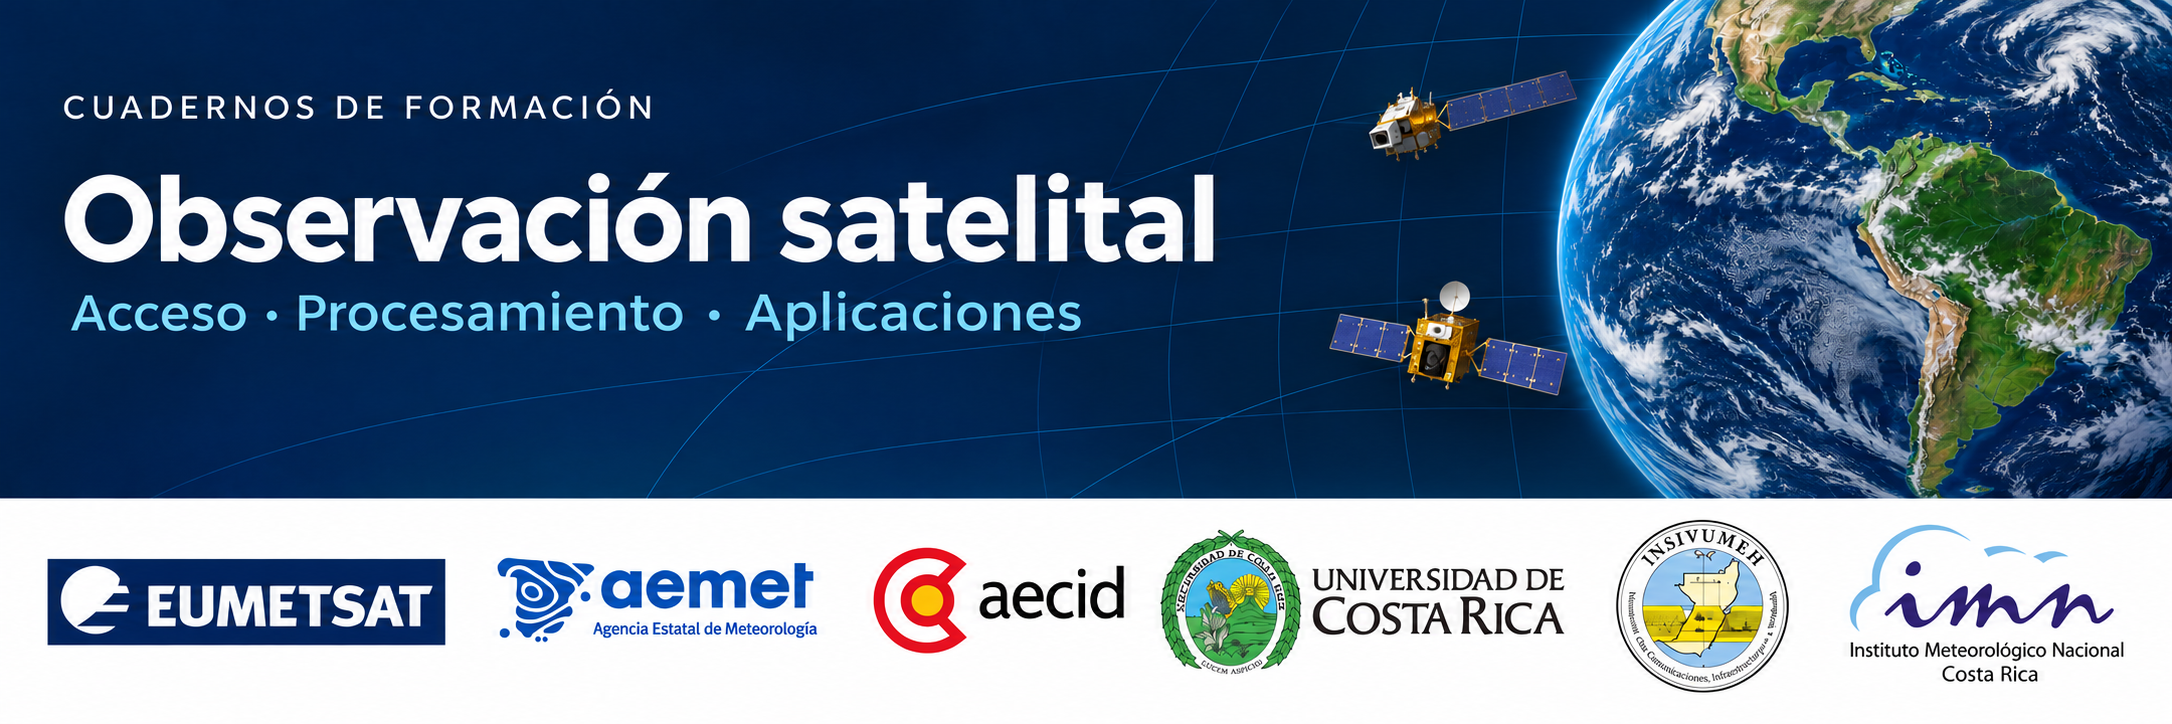

**PRODUCTOS Y APLICACIONES DE LOS SATÉLITES METEOROLÓGICOS**  
Fase presencial · Uruguay · Noviembre de 2026  
AEMET y EUMETSAT, con apoyo de AECID

# 05 · GPM / GMI · Microondas sobre Uruguay

*De la búsqueda de una pasada a la interpretación de 37 y 89 GHz*

| Ficha de la práctica | Detalle |
| :--- | :--- |
| Área temática | Microondas |
| Datos y acceso | NASA GES DISC / Earthdata · GPM_1BGMI V08 |
| Entorno | Google Colab o Jupyter / Anaconda de 64 bits |

> **Guía de trabajo:** lea el caso y sus requisitos; ejecute las celdas en orden; revise cada resultado antes de avanzar. Después, cambie un parámetro a la vez y conserve la procedencia de los datos.

**Recorrido:** comprender el caso · preparar el acceso · procesar · interpretar · guardar y reutilizar.

---


## Antes de comenzar · cuentas y acceso

**Para este cuaderno:** NASA Earthdata para descargar granulos. La consulta del catálogo es pública y el modo local no necesita iniciar sesión.

| Cuenta o servicio | Cuándo la necesita | Registro |
| :--- | :--- | :--- |
| Google | Solo si utiliza Colab; no se requiere para la ejecución local en Jupyter / Anaconda. | [Crear cuenta de Google](https://accounts.google.com/signup) |
| NASA Earthdata | NASA Earthdata para descargar granulos. La consulta del catálogo es pública y el modo local no necesita iniciar sesión. | [Crear cuenta](https://urs.earthdata.nasa.gov/users/new) |

**Crear una cuenta es un proceso guiado y sencillo.** Si ya utiliza Gmail o Google Drive, puede usar esa misma cuenta de Google. También puede crearla con un correo que ya tenga, sin abrir un Gmail nuevo: [guía en español](https://support.google.com/accounts/answer/27441?hl=es).

El registro Earthdata es gratuito y guiado: complete el formulario y active la cuenta con el enlace que recibe por correo. Use esa cuenta cuando aparezca la solicitud interactiva del cuaderno. No hace falta registrarse en PPS.

Antes de la sesión, compruebe que puede iniciar sesión y complete la verificación por correo si el portal la solicita. Cada participante utiliza su propia cuenta. Introduzca las credenciales únicamente cuando el cuaderno lo indique; no las escriba en celdas que vaya a compartir.

---


## Presentación del caso

Práctica guiada de 60–75 minutos · Jupyter/Anaconda de 64 bits o Google Colab  
**Preparado por el Dr. Marcial Garbanzo Salas para los participantes del curso.**  
Versión 1.2 · 18 de noviembre de 2026

**Pregunta de trabajo:** ¿qué estructura de precipitación y convección muestran las
microondas en el área de interés frente a Uruguay, y qué parte de esa área observó
realmente el satélite?

Utilizaremos **GPM_1BGMI, versión 08**, de NASA GES DISC / Earthdata. La consulta
del catálogo es pública; la descarga usa **NASA Earthdata Login**, sin registro PPS.
El caso se configura para **16–18 de noviembre de 2026**. La presencia o ausencia de
un ciclón se debe contrastar con los análisis meteorológicos del curso: el notebook
no presupone que una pasada capture su centro ni confirma por sí solo una clasificación.

**Al terminar podrá:** localizar granulos por fecha y región; distinguir el intervalo
orbital del horario observado en la región; leer los cuatro canales; aplicar
filtros de calidad; exportar PNG, NetCDF y un registro reproducible de la consulta.

**Selección de pasadas:** solo se generan mapas, estadísticas y subconjuntos de pasadas
con **al menos 40 % de cobertura válida estimada de toda la región**. La comparación
requiere datos válidos simultáneamente en los cuatro canales. Las pasadas descartadas
se conservan en el resumen para explicar el muestreo.


---

## 1 · Antes de ejecutar: qué medimos (8 min)

GMI es un **radiómetro de microondas pasivo** a bordo de GPM. Aquí se usa su temperatura
de brillo ($T_b$), en **kelvin**, no la temperatura física de la nube ni una tasa de lluvia.
**No existe un canal GMI de 98 GHz**: el canal de interés es **89 GHz**.

| Nombre en esta práctica | Frecuencia central | Polarización | Canal del instrumento | Índice Python en `S1/Tb` |
|---|---:|:---:|---:|---:|
| `37V` | 36.5 GHz | Vertical | 6 | 5 |
| `37H` | 36.5 GHz | Horizontal | 7 | 6 |
| `89V` | 89.0 GHz | Vertical | 8 | 7 |
| `89H` | 89.0 GHz | Horizontal | 9 | 8 |

Sobre el mar, 37 GHz ayuda a examinar la señal de agua líquida y precipitación;
89 GHz es más sensible a la dispersión por hielo. El contraste también depende de la
superficie, el viento, la geometría y la estructura de la atmósfera. Compare bandas,
asimetrías y coherencia espacial, sin convertir directamente $T_b$ en intensidad de lluvia.
Los tamaños de huella son diferentes entre frecuencias: compartir coordenadas o una
figura no vuelve idénticas sus resoluciones.

| Producto | Contenido | Uso en este ejercicio |
|---|---|---|
| GMI L1B `GPM_1BGMI` V08 | Temperaturas de brillo calibradas; NetCDF4 con grupos | **Fuente seleccionada** |
| GMI L1C `GPM_1CGPMGMI` | Temperaturas intercalibradas; variables diferentes | Otra práctica; no introducirlo en este lector |
| IMERG | Estimación de precipitación de varios satélites | Complemento, no sustituye los canales GMI |

**Pensar antes de buscar:** una órbita de unos 90 minutos no implica una observación
de Uruguay cada 90 minutos. Los huecos entre pasadas son parte del muestreo.

### ¿Qué significan vertical (V) y horizontal (H)?

Son dos **orientaciones del campo eléctrico de la radiación**, definidas respecto
de la geometría de observación y la superficie local. El plano de incidencia contiene
la dirección de observación y la normal a la superficie: **V** tiene el campo eléctrico
en ese plano y **H** perpendicular a él. No indican norte/sur ni izquierda/derecha
en el mapa, ni describen la dirección del viento.

La superficie y la atmósfera responden de forma distinta a ambas polarizaciones.
Sobre océano relativamente tranquilo y sin precipitación, la emisividad vertical suele
superar a la horizontal y es frecuente encontrar $T_{b,V}>T_{b,H}$. El viento, la espuma,
las nubes, la precipitación y las partículas de hielo modifican ese contraste.
Por eso se observan **dos polarizaciones en cada una de las dos frecuencias**.


---

## 2 · Preparar el entorno (5 min)

Ejecute de arriba hacia abajo con **Shift+Enter**. Se usan parámetros de texto y números,
sin `ipywidgets`. En Colab, abra este `.ipynb` con **Archivo → Subir notebook**.

La siguiente celda instala solamente paquetes faltantes en el kernel actual. Requiere
internet la primera vez. Si actualiza paquetes en una sesión ya abierta, reinicie el kernel.
Para Anaconda puede crear, opcionalmente, un entorno dedicado desde Anaconda Prompt:

```text
conda create -n gmi-uruguay -c conda-forge python=3.11 jupyterlab numpy pandas requests h5py xarray netcdf4 matplotlib cartopy earthaccess shapely pyproj
```

Active con `conda activate gmi-uruguay` y abra con `jupyter lab`.


In [1]:
import importlib.util
import subprocess
import sys

packages = {'numpy':'numpy', 'pandas':'pandas', 'requests':'requests', 'h5py':'h5py',
            'xarray':'xarray', 'netCDF4':'netCDF4', 'matplotlib':'matplotlib',
            'earthaccess':'earthaccess>=0.16', 'cartopy':'cartopy',
            'shapely':'shapely', 'pyproj':'pyproj'}
missing = [spec for module, spec in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
print('Entorno preparado. Python:', sys.version.split()[0])

Entorno preparado. Python: 3.13.18


In [2]:
from pathlib import Path
from datetime import datetime, timedelta, timezone
from urllib.parse import urlparse, unquote, urlencode
import importlib.metadata
import hashlib
import json
import warnings
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import numpy as np
import pandas as pd
import h5py
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, FileLink

plt.rcParams.update({'font.size': 10, 'axes.titleweight': 'bold', 'figure.dpi': 110})
print('Paquetes:', {p: importlib.metadata.version(p) for p in ['numpy','pandas','h5py','xarray','matplotlib']})

Paquetes: {'numpy': '2.4.6', 'pandas': '2.2.3', 'h5py': '3.14.0', 'xarray': '2025.12.0', 'matplotlib': '3.10.0'}


---

## 3 · Definir la pregunta espacial y temporal (5 min)

Modifique esta celda. **Longitudes oeste y latitudes sur son negativas.**
`BBOX` sigue el orden **oeste, sur, este, norte**, no latitud/longitud.
La caja incluye parte del continente para orientar la interpretación; las estadísticas
posteriores incluyen todos los centros observados en la caja, no solo el océano.

`MODO = "earthdata"` busca y descarga. `MODO = "local"` usa los originales que indique
en `ARCHIVOS_LOCALES` y no necesita consultar NASA ni iniciar sesión.
`VENTANA = "caso"` conserva el caso del curso; `"reciente"` usa las últimas 72 horas UTC.
La disponibilidad de hoy depende tanto del muestreo como de la publicación del archivo.

`COBERTURA_MINIMA = 0.40` exige al menos 40 % del área de la caja. Incluye tierra y mar.
`MAX_ARCHIVOS = 3` limita las pasadas **aceptadas**. `MAX_CANDIDATOS = 20` limita cuántas
se pueden evaluar; se descargan de una en una y se detiene la búsqueda cuando se reúne
la cantidad de pasadas aceptadas. El criterio se aplica por archivo, sin sumar pasadas.


In [3]:
MODO = 'earthdata'                  # 'earthdata' o 'local'
VENTANA = 'caso'                    # 'caso' o 'reciente'
INICIO_UTC = '2026-11-16T00:00:00Z'
FIN_UTC = '2026-11-18T23:59:59Z'
BBOX = (-60.0, -40.0, -45.0, -30.0) # oeste, sur, este, norte
PRODUCTO = 'GPM_1BGMI'
VERSION = '08'
PROVEEDOR = 'GES_DISC'
MAX_ARCHIVOS = 3                    # máximo de pasadas ACEPTADAS
MAX_CANDIDATOS = 20                 # máximo de originales a evaluar
COBERTURA_MINIMA = 0.40             # fracción de toda BBOX; 0.40 = 40 %
INDICES = None                     # None: los más recientes; o una lista, por ejemplo [0, 2]
ARCHIVOS_LOCALES = []               # ejemplo Windows: [r'C:\datos\1B.GPM.GMI....V08A.nc']
USAR_CARTOPY = True                 # False: gráficos lon/lat sin descargar costas
AVISO_ANTIGUEDAD_H = 12             # umbral didáctico configurable, no estándar del producto
BASE = Path('GMI_Uruguay')

if VENTANA == 'reciente':
    now = datetime.now(timezone.utc)
    INICIO_UTC = (now - timedelta(hours=72)).strftime('%Y-%m-%dT%H:%M:%SZ')
    FIN_UTC = now.strftime('%Y-%m-%dT%H:%M:%SZ')
assert MODO in ('earthdata', 'local') and VENTANA in ('caso', 'reciente')
assert 1 <= MAX_ARCHIVOS <= MAX_CANDIDATOS <= 100
assert 0 <= COBERTURA_MINIMA <= 1
west, south, east, north = BBOX
assert -180 <= west < east <= 180 and -90 <= south < north <= 90
start, end = pd.Timestamp(INICIO_UTC), pd.Timestamp(FIN_UTC)
assert start.tzinfo is not None and end.tzinfo is not None and start <= end
assert (end - start).total_seconds() <= 31 * 86400, 'Use hasta 31 días por consulta.'
DATA_DIR = BASE / 'originales'
RUN_DIR = BASE / ('resultados_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ'))
DATA_DIR.mkdir(parents=True, exist_ok=True)
RUN_DIR.mkdir(parents=True, exist_ok=True)
print('UTC:', INICIO_UTC, 'a', FIN_UTC)
print('Región:', BBOX, '| Modo:', MODO)
print('Resultados:', RUN_DIR.resolve())
print(f'Cobertura válida mínima: {100*COBERTURA_MINIMA:.0f} % | Meta: {MAX_ARCHIVOS} pasadas | Hasta {MAX_CANDIDATOS} candidatos.')

UTC: 2026-11-16T00:00:00Z a 2026-11-18T23:59:59Z
Región: (-60.0, -40.0, -45.0, -30.0) | Modo: earthdata
Resultados: /content/GMI_Uruguay/resultados_20261120T120136_882671Z
Cobertura válida mínima: 40 % | Meta: 3 pasadas | Hasta 20 candidatos.


---

## 4 · Buscar sin contraseña y examinar el catálogo (8 min)

Usamos la API pública **CMR** de NASA para ver archivos y enlaces. Después `earthaccess`
se encargará de la autenticación y la descarga HTTPS. Así se distingue **descubrir**
un dato de **acceder** a sus bytes. No hay dependencia del registro PPS.

Un resultado del catálogo es un **candidato**: la intersección del granulo con una caja
no garantiza que su centro de interés haya sido observado. El intervalo de un archivo
tampoco es necesariamente el horario de sus píxeles dentro de la región.


In [4]:
CMR_URL = 'https://cmr.earthdata.nasa.gov/search/granules.json'

def search_catalog(bbox, start, end):
    session = requests.Session()
    retries = Retry(total=2, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504])
    session.mount('https://', HTTPAdapter(max_retries=retries))
    params = {'short_name': PRODUCTO, 'version': VERSION, 'provider': PROVEEDOR,
              'bounding_box': ','.join(map(str, bbox)), 'temporal': start + ',' + end,
              'sort_key': '-start_date', 'page_size': 200, 'page_num': 1}
    entries = []
    try:
        for page in range(1, 6):
            params['page_num'] = page
            response = session.get(CMR_URL, params=params, timeout=(15, 45))
            response.raise_for_status()
            batch = response.json()['feed']['entry']
            entries.extend(batch)
            if len(batch) < 200:
                break
        else:
            raise RuntimeError('Consulta demasiado grande: reduzca la región o las fechas.')
    except requests.RequestException as exc:
        raise RuntimeError('No se pudo consultar CMR. Revise internet y el servicio. No significa que no existan pasadas.') from exc
    finally:
        session.close()
    rows = []
    seen = set()
    for entry in entries:
        links = [link['href'] for link in entry.get('links', [])
                 if not link.get('inherited', False) and '/data#' in link.get('rel', '')
                 and link.get('href', '').startswith('https://')
                 and urlparse(link['href']).path.lower().endswith('.nc')]
        if not links:
            continue
        url = links[0]
        filename = unquote(Path(urlparse(url).path).name)
        if filename in seen:
            continue
        seen.add(filename)
        rows.append({'archivo': filename, 'inicio_granulo_UTC': entry['time_start'],
                     'fin_granulo_UTC': entry.get('time_end', entry['time_start']),
                     'MB_catalogo_aprox': float(entry.get('granule_size') or 'nan'),
                     'url': url, 'cmr_id': entry['id']})
    columns = ['archivo','inicio_granulo_UTC','fin_granulo_UTC','MB_catalogo_aprox','url','cmr_id']
    table = pd.DataFrame(rows, columns=columns).sort_values('inicio_granulo_UTC', ascending=False).reset_index(drop=True)
    return table, entries

catalogo = pd.DataFrame()
catalogo_original = []
if MODO == 'earthdata':
    catalogo, catalogo_original = search_catalog(BBOX, INICIO_UTC, FIN_UTC)
    catalogo.to_csv(RUN_DIR / 'catalogo.csv', index=False)
    (RUN_DIR / 'catalogo_cmr.json').write_text(json.dumps(catalogo_original, indent=2), encoding='utf-8')
    display(catalogo.drop(columns=['url', 'cmr_id']))
    print(f'{len(catalogo)} granulos con enlace HTTPS NetCDF4; ordenados del más reciente al más antiguo.')
    if catalogo.empty:
        print('Sin resultados descargables en esta consulta. No se cambia la fecha automáticamente.')
        print('Revise publicación, ventana temporal y región. Un vacío no significa ausencia de precipitación.')
    else:
        latest = pd.to_datetime(catalogo['fin_granulo_UTC'], utc=True).max()
        print('Fin del granulo más reciente en el catálogo:', latest)
        print('Todavía NO es la hora de observación dentro de la caja.')
else:
    print('Modo local: se omite la consulta del catálogo.')

,archivo,inicio_granulo_UTC,fin_granulo_UTC,MB_catalogo_aprox
0,1B.GPM.GMI.TB2021.20261117-S205753-E223105.072...,2026-11-17T20:57:53.288Z,2026-11-17T22:31:06.497Z,40.691152
1,1B.GPM.GMI.TB2021.20261116-S231248-E004600.072...,2026-11-16T23:12:48.381Z,2026-11-17T00:46:01.543Z,40.676347
2,1B.GPM.GMI.TB2021.20261116-S091349-E104701.072...,2026-11-16T09:13:49.216Z,2026-11-16T10:47:02.444Z,40.541526
3,1B.GPM.GMI.TB2021.20261116-S074036-E091348.072...,2026-11-16T07:40:36.032Z,2026-11-16T09:13:49.216Z,40.513695


4 granulos con enlace HTTPS NetCDF4; ordenados del más reciente al más antiguo.
Fin del granulo más reciente en el catálogo: 2026-11-17 22:31:06.497000+00:00
Todavía NO es la hora de observación dentro de la caja.


**Pausa didáctica.** ¿Hay datos del día que le interesa? ¿Es el intervalo de un archivo
lo mismo que el horario de la pasada sobre Uruguay? No use un archivo anterior sin
declarar su fecha. La ruta de archivo científico GES DISC no garantiza la latencia de PPS NRT.


In [5]:
seleccion = pd.DataFrame()
if MODO == 'earthdata' and not catalogo.empty:
    if INDICES is None:
        seleccion = catalogo.head(MAX_CANDIDATOS).copy()
    else:
        indices = list(dict.fromkeys(INDICES))
        if not indices or any(not isinstance(i, int) or i < 0 or i >= len(catalogo) for i in indices):
            raise ValueError('INDICES debe contener índices válidos de la tabla anterior.')
        if len(indices) > MAX_CANDIDATOS:
            raise ValueError('La selección supera MAX_CANDIDATOS; ajuste ambos parámetros de forma explícita.')
        seleccion = catalogo.iloc[indices].copy()
    display(seleccion.drop(columns=['url', 'cmr_id']))
    print('Candidatos a evaluar:', len(seleccion), '| Se descargan de uno en uno, hasta reunir', MAX_ARCHIVOS, 'aceptados.')
    print('Tamaño máximo de todos los candidatos (MB aprox.; puede descargarse menos):', round(seleccion.MB_catalogo_aprox.sum(), 1))

,archivo,inicio_granulo_UTC,fin_granulo_UTC,MB_catalogo_aprox
0,1B.GPM.GMI.TB2021.20261117-S205753-E223105.072...,2026-11-17T20:57:53.288Z,2026-11-17T22:31:06.497Z,40.691152
1,1B.GPM.GMI.TB2021.20261116-S231248-E004600.072...,2026-11-16T23:12:48.381Z,2026-11-17T00:46:01.543Z,40.676347
2,1B.GPM.GMI.TB2021.20261116-S091349-E104701.072...,2026-11-16T09:13:49.216Z,2026-11-16T10:47:02.444Z,40.541526
3,1B.GPM.GMI.TB2021.20261116-S074036-E091348.072...,2026-11-16T07:40:36.032Z,2026-11-16T09:13:49.216Z,40.513695


Candidatos a evaluar: 4 | Se descargan de uno en uno, hasta reunir 3 aceptados.
Tamaño máximo de todos los candidatos (MB aprox.; puede descargarse menos): 162.4


---

## 5 · Descargar con Earthdata Login o usar archivos locales (5 min)

Necesita una cuenta gratuita de [NASA Earthdata Login](https://urs.earthdata.nasa.gov/).
Es **usuario y contraseña de Earthdata**: no son el correo de PPS ni key/secret de EUMETSAT.
Los candidatos se descargan de uno en uno y se reutilizan si ya están en disco.
La contraseña se introduce en el diálogo oculto. No escriba credenciales en una celda.
`persist=False` evita guardar una nueva copia de las credenciales en disco.

Si NASA exige autorizar su aplicación de archivo o aceptar condiciones, complete ese
paso en el navegador con su cuenta y vuelva a ejecutar la celda. También puede descargar
desde [Earthdata Search](https://search.earthdata.nasa.gov/search?q=GPM_1BGMI_08), colocar los
originales en una carpeta y volver a la sección 3 con `MODO='local'` y las rutas explícitas.
En Colab, puede subir un archivo desde el panel **Archivos** y usar `/content/nombre.nc`.
Se obtiene primero un candidato para inspeccionar su estructura. Los demás se obtienen en la sección 8, solo mientras hagan falta pasadas aceptadas.


In [6]:
archivos = []
errores_descarga = []
_auth_gmi = None

def obtener_archivo(row):
    """Descarga un candidato solo cuando se necesita; conserva los originales."""
    global _auth_gmi
    cached = DATA_DIR / row['archivo']
    try:
        if cached.is_file():
            if not h5py.is_hdf5(cached):
                raise ValueError(f'Archivo local inválido: {cached}. Muévalo fuera de originales antes de reintentar.')
        else:
            import earthaccess
            if _auth_gmi is None:
                _auth_gmi = earthaccess.login(strategy='interactive', persist=False)
                if not _auth_gmi.authenticated:
                    raise RuntimeError('Earthdata no autenticó la sesión.')
            result = earthaccess.download([row['url']], local_path=str(DATA_DIR), provider=PROVEEDOR, threads=1)
            if not result or not cached.is_file() or not h5py.is_hdf5(cached):
                raise ValueError('La respuesta no contiene el NetCDF4/HDF5 original esperado.')
        cached = cached.resolve()
        if cached not in archivos:
            archivos.append(cached)
        return cached
    except Exception as exc:
        errores_descarga.append({'archivo': row['archivo'], 'tipo_error': type(exc).__name__})
        print('No se completó:', row['archivo'], '|', type(exc).__name__)
        print('Revise autenticación, autorización de GES DISC, conectividad y espacio libre.')
        return None

if MODO == 'local':
    archivos = list(dict.fromkeys(Path(p).expanduser().resolve() for p in ARCHIVOS_LOCALES))
    if not archivos or any(not p.is_file() for p in archivos):
        raise FileNotFoundError('Indique archivos existentes en ARCHIVOS_LOCALES y vuelva a ejecutar desde la sección 3.')
elif seleccion.empty:
    print('No hay candidatos; no se solicita una contraseña.')
else:
    primero = obtener_archivo(seleccion.iloc[0].to_dict())
    print('El resto se evaluará de uno en uno en la sección 8.')
print('Originales locales identificados:', len(archivos))
for path in archivos:
    print(path.name, '|', round(path.stat().st_size / 1e6, 2), 'MB')

Enter your Earthdata Login username: mgarbanzo
Enter your Earthdata password: ··········


  0%|          | 0/1 [00:00<?, ?it/s]

El resto se evaluará de uno en uno en la sección 8.
Originales locales identificados: 1
1B.GPM.GMI.TB2021.20261117-S205753-E223105.072159.V08A.nc | 42.67 MB


---

## 6 · Inspeccionar y leer solo los canales necesarios (10 min)

En `S1`, `Latitude` y `Longitude` identifican centros de observación; `Tb` tiene nueve
canales. `ScanTime` aporta UTC por barrido. El lector usa los índices **5, 6, 7 y 8**,
enmascara rellenos, exige `scanStatus/dataQuality == 0` y `RFIFlag == 0` en cada frecuencia.
Rechaza temperaturas fuera del rango documentado de 0–400 K. Es un filtrado inicial
basado en esos campos; no reemplaza una evaluación de todos los indicadores instrumentales.

**No todos los puntos de la caja tienen observación.** Primero se filtran coordenadas y
hora real de barrido. Luego se comprueba la calidad de cada canal; valores rechazados
quedan como `NaN`. Nunca se transforman en ceros ni se rellenan entre pasadas.


In [7]:
if archivos:
    with h5py.File(archivos[0], 'r') as f:
        for key in ['S1/Latitude','S1/Longitude','S1/Tb','S1/scanStatus/dataQuality','S1/RFIFlag']:
            if key in f:
                print(key, '| dimensiones:', f[key].shape, '| tipo:', f[key].dtype)
            else:
                print('NO ENCONTRADO:', key)
else:
    print('Sin originales todavía; las secciones de procesamiento se omitirán.')

S1/Latitude | dimensiones: (2983, 221) | tipo: float32
S1/Longitude | dimensiones: (2983, 221) | tipo: float32
S1/Tb | dimensiones: (2983, 221, 9) | tipo: float32
S1/scanStatus/dataQuality | dimensiones: (2983,) | tipo: int8
S1/RFIFlag | dimensiones: (2983, 221, 5) | tipo: int16


In [8]:
CHANNELS = {'37V': 5, '37H': 6, '89V': 7, '89H': 8}
FREQUENCIES = {'37V': 36.5, '37H': 36.5, '89V': 89.0, '89H': 89.0}

def read_numeric(dataset, selection=()):
    """Enmascara relleno ANTES de aplicar scale_factor/add_offset."""
    a = np.asarray(dataset[selection], dtype=np.float64)
    valid = np.isfinite(a)
    for key in ('_FillValue', 'missing_value', 'CodeMissingValue'):
        if key in dataset.attrs:
            for value in np.asarray(dataset.attrs[key]).ravel():
                try:
                    valid &= a != float(value)
                except (TypeError, ValueError):
                    pass
    # El formato GPM tambien utiliza rellenos negativos sin atributo CF.
    valid &= a > -9990
    scale = float(np.asarray(dataset.attrs.get('scale_factor', 1)).ravel()[0])
    offset = float(np.asarray(dataset.attrs.get('add_offset', 0)).ravel()[0])
    return np.where(valid, a * scale + offset, np.nan)

def scan_times(group):
    """UTC asociado a cada barrido; conserva milisegundos y cruce de medianoche."""
    required = ['Year', 'Month', 'DayOfMonth', 'Hour', 'Minute', 'Second']
    if any(k not in group for k in required):
        raise ValueError('Faltan componentes de S1/ScanTime; no se inventara una hora.')
    v = {k: read_numeric(group[k]) for k in required}
    base = pd.to_datetime({'year': v['Year'], 'month': v['Month'],
                           'day': v['DayOfMonth']}, errors='coerce', utc=True)
    valid = ((v['Hour'] >= 0) & (v['Hour'] <= 23) &
             (v['Minute'] >= 0) & (v['Minute'] <= 59) &
             (v['Second'] >= 0) & (v['Second'] <= 60))
    ms = read_numeric(group['MilliSecond']) if 'MilliSecond' in group else np.zeros(len(base))
    valid &= (ms >= 0) & (ms < 1000)
    seconds = v['Hour'] * 3600 + v['Minute'] * 60 + v['Second'] + ms / 1000
    t = pd.DatetimeIndex(base + pd.to_timedelta(seconds, unit='s'))
    return t.where(valid)

def read_gmi(path, bbox, start, end):
    """Lee un granulo original 1BGMI. Devuelve centros observados en region y periodo.

    Mantiene las observaciones geometricas aunque su Tb sea invalida, de modo que
    se pueda distinguir fuera de barrido de observacion rechazada por calidad.
    No interpola ni rellena huecos. Orden de bbox: oeste, sur, este, norte.
    """
    path = Path(path)
    west, south, east, north = bbox
    if not (-180 <= west < east <= 180 and -90 <= south < north <= 90):
        raise ValueError('Caja invalida. Esta practica no admite cruce del antimeridiano.')
    t0, t1 = pd.Timestamp(start), pd.Timestamp(end)
    if t0.tzinfo is None or t1.tzinfo is None or t0 > t1:
        raise ValueError('Fechas invalidas: use UTC con sufijo Z e inicio <= fin.')
    if not h5py.is_hdf5(path):
        raise ValueError(f'{path.name}: no es NetCDF4/HDF5; podria ser una pagina de login o una descarga incompleta.')
    with h5py.File(path, 'r') as f:
        required = ['S1/Latitude', 'S1/Longitude', 'S1/Tb', 'S1/ScanTime',
                    'S1/scanStatus/dataQuality', 'S1/RFIFlag']
        missing = [k for k in required if k not in f]
        if missing:
            raise ValueError(f'{path.name}: faltan {missing}. Use el archivo original GPM_1BGMI V08, no IMERG ni L1C.')
        lat = read_numeric(f['S1/Latitude'])
        lon = read_numeric(f['S1/Longitude'])
        if lat.ndim != 2 or lat.shape != lon.shape:
            raise ValueError('Latitud/longitud deben tener dimensiones (barrido, pixel).')
        nscan, npix = lat.shape
        times = scan_times(f['S1/ScanTime'])
        if len(times) != nscan:
            raise ValueError('ScanTime no coincide con el numero de barridos.')
        if f['S1/Tb'].shape != (nscan, npix, 9):
            raise ValueError(f"Dimensiones inesperadas de Tb: {f['S1/Tb'].shape}; se esperaba ({nscan}, {npix}, 9).")
        if f['S1/RFIFlag'].shape != (nscan, npix, 5):
            raise ValueError('RFIFlag no tiene las 5 frecuencias esperadas en S1.')
        geovalid = (np.isfinite(lat) & np.isfinite(lon) & (abs(lat) <= 90) & (abs(lon) <= 180))
        in_box = geovalid & (lon >= west) & (lon <= east) & (lat >= south) & (lat <= north)
        in_time = np.asarray((times >= t0) & (times <= t1) & times.notna())
        spatial_scans = in_box.any(axis=1)
        roi = in_box & in_time[:, None]
        rows, cols = np.where(roi)
        if not len(rows):
            return None, {'archivo': path.name, 'estado': 'sin_centros_en_region_y_periodo',
                          'centros_en_caja_sin_filtro_temporal': int(in_box.sum())}
        # Solo se cargan barridos de interes y 4 de los 9 canales.
        a, b = int(rows.min()), int(rows.max()) + 1
        ii = rows - a
        dq = read_numeric(f['S1/scanStatus/dataQuality'])
        if dq.shape != (nscan,):
            raise ValueError('dataQuality debe tener un valor por barrido.')
        variables = {}
        for label, channel in CHANNELS.items():
            tb = read_numeric(f['S1/Tb'], (slice(a, b), slice(None), channel))[ii, cols]
            frequency_index = 3 if label.startswith('37') else 4
            rfi = read_numeric(f['S1/RFIFlag'], (slice(a, b), slice(None), frequency_index))[ii, cols]
            good = (dq[rows] == 0) & (rfi == 0) & np.isfinite(tb) & (tb >= 0) & (tb <= 400)
            variables['Tb_' + label] = ('observation', np.where(good, tb, np.nan).astype('float32'))
            variables['valid_' + label] = ('observation', good.astype('int8'))
            if 'RFI_' + label[:2] not in variables:
                variables['RFI_' + label[:2]] = ('observation', rfi.astype('float32'))
        variables['scan_dataQuality'] = ('observation', dq[rows].astype('float32'))
        variables['scan_index'] = ('observation', rows.astype('int32'))
        variables['pixel_index'] = ('observation', cols.astype('int32'))
        ds = xr.Dataset(variables, coords={
            'latitude': ('observation', lat[roi].astype('float32')),
            'longitude': ('observation', lon[roi].astype('float32')),
            'time': ('observation', times[rows].tz_convert('UTC').tz_localize(None).to_numpy())},
            attrs={'title': 'GPM GMI: observaciones de 36.5 y 89 GHz en la region de estudio',
                   'source_file': path.name, 'product': 'GPM_1BGMI',
                   'product_doi': '10.5067/GPM/GMI/GPM/1B/08',
                   'bbox_west_south_east_north': json.dumps(list(bbox)),
                   'requested_start_utc': str(t0), 'requested_end_utc': str(t1),
                   'quality_filter': 'dataQuality == 0; RFIFlag == 0 por frecuencia; Tb en [0,400] K; sin rellenos',
                   'sampling': 'Centros de IFOV nativos. Sin interpolacion. time es UTC del barrido, no hora individual exacta de cada pixel.',
                   'Conventions': 'CF-1.10'})
    ds['latitude'].attrs.update(units='degrees_north', standard_name='latitude')
    ds['longitude'].attrs.update(units='degrees_east', standard_name='longitude')
    ds['time'].attrs.update(standard_name='time', long_name='UTC asociado al barrido')
    for label in CHANNELS:
        pol_name = 'vertical (V)' if label.endswith('V') else 'horizontal (H)'
        ds['Tb_' + label].attrs.update(units='K', long_name=f'Tb {FREQUENCIES[label]:g} GHz | Polarización {pol_name}',
                                     frequency_GHz=FREQUENCIES[label], polarization=label[-1],
                                     source_variable='S1/Tb', source_channel_index_zero_based=CHANNELS[label])
        ds['valid_' + label].attrs.update(long_name='Pasa los filtros aplicados', flag_values=np.array([0, 1], dtype='int8'),
                                        flag_meanings='rejected accepted')
    for freq in ['37', '89']:
        ds['PD_' + freq] = ds['Tb_' + freq + 'V'] - ds['Tb_' + freq + 'H']
        ds['PD_' + freq].attrs.update(units='K', long_name=f'{FREQUENCIES[freq+"V"]:g} GHz | Vertical menos horizontal (V − H)',
                                     formula=f'Tb_{freq}V - Tb_{freq}H', description='Diferencia de temperaturas de brillo, no cociente ni porcentaje.')
    valid_any = np.column_stack([ds['valid_' + k].values.astype(bool) for k in CHANNELS]).any(axis=1)
    report = {'archivo': path.name, 'estado': 'ok' if valid_any.any() else 'todos_rechazados_por_calidad',
              'inicio_region_UTC': str(pd.Timestamp(ds.time.values.min()).tz_localize('UTC')),
              'fin_region_UTC': str(pd.Timestamp(ds.time.values.max()).tz_localize('UTC')),
              'centros_en_region_y_periodo': len(rows), 'centros_con_algun_canal_valido': int(valid_any.sum()),
              'barridos_en_region_y_periodo': len(np.unique(rows))}
    for label in CHANNELS:
        report['validos_' + label] = int(ds['valid_' + label].sum())
    return ds, report

---

## 7 · Cómo leer las dos figuras de cada pasada

### Figura 1: cuatro temperaturas de brillo

| Posición | Canal | Qué representa el color |
|---|---|---|
| Arriba, izquierda | 37V: 36.5 GHz, **vertical** | Temperatura de brillo de ese canal, en K |
| Arriba, derecha | 37H: 36.5 GHz, **horizontal** | Temperatura de brillo de ese canal, en K |
| Abajo, izquierda | 89V: 89 GHz, **vertical** | Temperatura de brillo de ese canal, en K |
| Abajo, derecha | 89H: 89 GHz, **horizontal** | Temperatura de brillo de ese canal, en K |

Comparar **izquierda y derecha** mantiene la frecuencia y cambia la polarización.
Comparar **arriba y abajo** mantiene la polarización y cambia la frecuencia.
Todos los paneles usan la misma escala de Tb. En esta paleta, los valores bajos
son rojizos/anaranjados y los altos azulados/morados: lea la barra, no asocie rojo
automáticamente con una temperatura alta o lluvia intensa.

Sobre el océano, la emisión de agua líquida y lluvia puede elevar Tb a 37 GHz respecto
del fondo marino. A 89 GHz, la dispersión por hielo puede disminuir Tb y destacar
estructuras convectivas. Son sensibilidades predominantes, no una separación perfecta:
en ambas frecuencias intervienen superficie y atmósfera, y sus huellas tienen distinto tamaño.

### Figura 2: diferencia entre polarizaciones, no una razón

Los dos mapas siguientes calculan, para cada centro con ambas polarizaciones válidas:

$$PD_{37}=T_{b,37V}-T_{b,37H},\qquad PD_{89}=T_{b,89V}-T_{b,89H}.$$

**Izquierda: 37 GHz. Derecha: 89 GHz.** En esta segunda figura, cada panel combina V y H:
ninguno representa una polarización por separado. PD significa *polarization difference*.
Su unidad sigue siendo **kelvin (K)**. Un cociente $T_{b,V}/T_{b,H}$ sería adimensional;
ese cociente **no se calcula** en este notebook.

| Valor de PD | Lectura directa |
|---|---|
| Positivo | Tb vertical es mayor que Tb horizontal |
| Cercano a cero | Ambas temperaturas de brillo son similares |
| Negativo | Tb horizontal es mayor que Tb vertical |

**Ejemplo didáctico, no una observación del caso:** si $T_{b,V}=250$ K y $T_{b,H}=230$ K,
entonces $PD=20$ K. Es una resta; no es 20 %, ni una tasa de lluvia.

**¿Para qué sirve?** El océano suele producir un contraste V–H apreciable.
La precipitación puede reducir la contribución polarizada de la superficie; en áreas
convectivas con dispersión intensa por hielo puede observarse Tb baja junto con PD pequeña.
Sin embargo, **PD pequeña por sí sola no demuestra convección**: tierra firme, propiedades
de la superficie y microfísica también influyen. Las partículas de hielo orientadas pueden
producir sus propias diferencias de polarización. Compare PD con los mapas de Tb,
la costa y otras observaciones. No se aplica un umbral universal de PD para clasificar lluvia.

La escala de PD es distinta a la de Tb: **un mismo color entre las dos figuras no significa
el mismo valor**. PD tampoco es una temperatura corregida por polarización (PCT).

### Qué representan los símbolos y anotaciones

Los mapas representan **centros de observación**, sin interpolación. El tamaño del símbolo
no representa exactamente la huella instrumental. Gris indica que no se representa un dato
en ese lugar; no equivale a ausencia de precipitación. Las costas de Natural Earth se guardan
en caché por Cartopy; sin cartografía disponible se conservan ejes geográficos.

`n` es el número de centros con datos válidos en cada panel. La **cobertura válida (%)**
es otra medida: porcentaje estimado del área de BBOX muestreada con los cuatro canales
válidos; es el valor usado para exigir al menos 40 %. No es PD ni porcentaje de lluvia.

Después de las figuras, la sección 9 muestra la antigüedad y una tabla de estadísticos:
`min_K`, `p10_K` (percentil 10), `mediana_K` y `max_K`, todos de Tb en kelvin por canal.
No contiene una razón entre canales.


In [9]:
def prepare_maps(use_cartopy=True):
    """Descarga cartografia solo si hace falta; puede trabajar sin ella."""
    if not use_cartopy:
        return None
    try:
        import cartopy.crs as ccrs
        from cartopy.io import shapereader
        # Pre-carga: un fallo de red no debe ocurrir al guardar la figura.
        coasts = list(shapereader.Reader(shapereader.natural_earth('110m', 'physical', 'coastline')).geometries())
        borders = list(shapereader.Reader(shapereader.natural_earth('110m', 'cultural', 'admin_0_boundary_lines_land')).geometries())
        return ccrs, coasts, borders
    except Exception as exc:
        warnings.warn(f'Cartografia no disponible ({type(exc).__name__}). Se usaran ejes lon/lat, sin costas.')
        return None

def regional_coverage(ds, bbox):
    """Fraccion aproximada del area de BBOX cubierta por una malla de centros vecinos.

    Conserva huecos y exige continuidad de indices, tiempo y distancia. No extiende
    la malla mas alla de sus centros exteriores ni usa una envolvente convexa.
    La cobertura util exige validez simultanea de los cuatro canales.
    """
    from pyproj import CRS, Transformer, Geod
    from shapely.geometry import Polygon
    from shapely.ops import unary_union
    west, south, east, north = bbox
    projection = CRS.from_proj4(f'+proj=laea +lat_0={(south+north)/2} +lon_0={(west+east)/2} +datum=WGS84 +units=m')
    project = Transformer.from_crs('EPSG:4326', projection, always_xy=True)
    edge = np.linspace(0, 1, 101)
    boundary_lon = np.r_[west+(east-west)*edge, np.full(101,east), east-(east-west)*edge, np.full(101,west)]
    boundary_lat = np.r_[np.full(101,south), south+(north-south)*edge, np.full(101,north), north-(north-south)*edge]
    region = Polygon(np.column_stack(project.transform(boundary_lon, boundary_lat)))
    total_area = region.area
    if not np.isfinite(total_area) or total_area <= 0:
        raise ValueError('No se pudo calcular el area de la region.')
    rows = ds.scan_index.values.astype(int)
    cols = ds.pixel_index.values.astype(int)
    shape = (int(rows.max()-rows.min()+1), int(cols.max()-cols.min()+1))
    rr, cc = rows-rows.min(), cols-cols.min()
    lon = np.full(shape, np.nan)
    lat = np.full(shape, np.nan)
    stamp = np.full(shape, np.nan)
    good = np.zeros(shape, dtype=bool)
    lon[rr,cc], lat[rr,cc] = ds.longitude.values, ds.latitude.values
    stamp[rr,cc] = ds.time.values.astype('datetime64[ms]').astype('int64') / 1000
    good[rr,cc] = np.column_stack([ds['valid_'+k].values.astype(bool) for k in CHANNELS]).all(axis=1)
    def corners(a):
        return np.stack([a[:-1,:-1],a[:-1,1:],a[1:,1:],a[1:,:-1]],axis=-1).reshape(-1,4)
    lons, lats, times, quality = map(corners, [lon,lat,stamp,good])
    geometric = np.isfinite(lons).all(axis=1) & np.isfinite(lats).all(axis=1) & np.isfinite(times).all(axis=1)
    idx = np.flatnonzero(geometric)
    geometries, valid_geometries = [], []
    if len(idx):
        lons, lats, times, quality = lons[idx], lats[idx], times[idx], quality[idx]
        # No unir saltos de telemetria, barridos separados ni geolocalizacion discontinua.
        geod = Geod(ellps='WGS84')
        distances = geod.inv(lons, lats, np.roll(lons,-1,axis=1), np.roll(lats,-1,axis=1))[2]
        continuous = (distances <= 60000).all(axis=1) & (np.ptp(times,axis=1) <= 10)
        x, y = project.transform(lons, lats)
        for i in np.flatnonzero(continuous):
            polygon = Polygon(np.column_stack([x[i],y[i]]))
            if polygon.is_valid and not polygon.is_empty and polygon.area > 0:
                geometries.append(polygon)
                if quality[i].all():
                    valid_geometries.append(polygon)
    def fraction(polygons):
        area = unary_union(polygons).intersection(region).area if polygons else 0.0
        return float(np.clip(area/total_area,0,1))
    return {'cobertura_geometrica_fraccion': fraction(geometries),
            'cobertura_valida_fraccion': fraction(valid_geometries),
            'area_region_km2': total_area/1e6}

def meets_coverage(fraction, minimum=0.40):
    """El umbral es inclusivo; no se redondea para decidir."""
    return bool(np.isfinite(fraction) and fraction >= minimum)

def map_panel(ax, bbox, map_context):
    west, south, east, north = bbox
    ax.set_facecolor('#e9eef2')
    if map_context:
        ccrs, coasts, borders = map_context
        crs = ccrs.PlateCarree()
        ax.set_extent([west, east, south, north], crs=crs)
        ax.add_geometries(coasts, crs, facecolor='none', edgecolor='#243744', linewidth=0.7, zorder=4)
        ax.add_geometries(borders, crs, facecolor='none', edgecolor='#596c77', linewidth=0.5, zorder=4)
        gl = ax.gridlines(draw_labels=True, linewidth=0.4, alpha=0.4)
        gl.top_labels = False
        gl.right_labels = False
        gl.xlabel_style = gl.ylabel_style = {'size': 8}
        kwargs = {'transform': crs}
    else:
        ax.set_xlim(west, east)
        ax.set_ylim(south, north)
        ax.set_aspect(1 / np.cos(np.deg2rad((south + north) / 2)))
        ax.set_xlabel('Longitud (grados)')
        ax.set_ylabel('Latitud (grados)')
        ax.grid(alpha=0.25)
        kwargs = {}
    if west < -56.1645 < east and south < -34.9011 < north:
        ax.plot(-56.1645, -34.9011, 'ko', markersize=3, zorder=6, **kwargs)
        ax.text(-56.02, -34.9, 'Montevideo', fontsize=7, zorder=6, **kwargs)
    return kwargs

def plot_gmi(ds, bbox, map_context=None, differences=False, output=None):
    keys = ['PD_37', 'PD_89'] if differences else ['Tb_37V', 'Tb_37H', 'Tb_89V', 'Tb_89H']
    subplot_kw = {'projection': map_context[0].PlateCarree()} if map_context else {}
    fig, axs = plt.subplots(1 if differences else 2, 2, figsize=(14, 5.7 if differences else 10.6),
                            subplot_kw=subplot_kw, layout='constrained')
    limits = (-20, 100) if differences else (80, 310)
    cmap = 'viridis' if differences else 'turbo_r'
    for ax, key in zip(np.atleast_1d(axs).ravel(), keys):
        kw = map_panel(ax, bbox, map_context)
        good = np.isfinite(ds[key].values)
        scatter = ax.scatter(ds.longitude.values[good], ds.latitude.values[good], c=ds[key].values[good],
                             s=7, marker='s', linewidths=0, cmap=cmap, vmin=limits[0], vmax=limits[1], **kw)
        label = ds[key].attrs['long_name']
        ax.set_title(label + f' | n={int(good.sum()):,}', fontsize=10, loc='left')
        if not good.any():
            ax.text(0.5, 0.5, 'SIN DATOS VALIDOS', transform=ax.transAxes, ha='center', color='#912d2d')
        fig.colorbar(scatter, ax=ax, shrink=0.85, pad=0.025, label='Diferencia V − H (K)' if differences else 'Temperatura de brillo (K)', extend='both')
    start = pd.Timestamp(ds.time.values.min()).strftime('%Y-%m-%d %H:%M:%S')
    end = pd.Timestamp(ds.time.values.max()).strftime('%Y-%m-%d %H:%M:%S')
    title = 'GPM / GMI | Diferencia de polarización: Tb(V) − Tb(H), en K' if differences else 'GPM / GMI | Temperaturas de brillo a 36.5 y 89 GHz'
    coverage = ds.attrs.get('cobertura_valida_pct')
    coverage_text = f' | Cobertura valida: {coverage:.1f} %' if coverage is not None else ''
    fig.suptitle(f'{title}\n{start} a {end} UTC en la region{coverage_text}', fontsize=15, color='#073b56')
    guide = 'PD > 0: V mayor que H; PD = 0: iguales; PD < 0: H mayor que V. No es un cociente.' if differences else 'Izquierda: polarización vertical (V). Derecha: horizontal (H). Arriba: 36.5 GHz. Abajo: 89 GHz.'
    fig.supxlabel(guide + '\nCentros de observación; sin interpolación. Gris: sin dato representado.\nNASA GES DISC | ' + ds.attrs['source_file'], fontsize=8)
    if output:
        fig.savefig(output, dpi=180, facecolor='white')
    return fig

In [10]:
def write_subset(ds, path):
    encoding = {k: {'zlib': True, 'complevel': 4} for k in ds.data_vars}
    encoding['time'] = {'units': 'milliseconds since 1970-01-01', 'dtype': 'int64', 'calendar': 'proleptic_gregorian'}
    ds.to_netcdf(path, engine='netcdf4', encoding=encoding)

def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

---

## 8 · Filtrar por cobertura y procesar las pasadas aceptadas (10 min)

**Criterio:** cobertura válida estimada **≥ 40 % del área completa de BBOX**.
El denominador es el área geográfica de la caja, no el número de píxeles descargados.
Se exige validez simultánea en 37V, 37H, 89V y 89H para que la comparación sea útil.

La cobertura se aproxima mediante pequeños cuadriláteros entre centros vecinos de
barridos y píxeles consecutivos, proyectados a un sistema que conserva áreas (Lambert
azimutal equivalente). Se recortan a la caja y se unen sin contar dos veces los solapamientos.
No se conectan huecos de índices, saltos temporales mayores a 10 s ni lados mayores a 60 km.
No se extrapola fuera de los centros extremos: es una estimación conservadora del área
muestreada, **no la unión exacta de las huellas de antena** ni una interpolación de Tb.

El resumen muestra cobertura geométrica y cobertura válida, ambas en porcentaje.
La decisión usa la fracción sin redondear: **40 % se acepta; menos de 40 % se descarta**.
Solo las aceptadas generan figuras, estadísticas y NetCDF; todas las evaluadas quedan
registradas. No se mezclan horarios para alcanzar el umbral. Si ninguna cumple, se
informa claramente; cambie de forma explícita la región, las fechas o el límite de candidatos.



Evaluando: 1B.GPM.GMI.TB2021.20261117-S205753-E223105.072159.V08A.nc
DESCARTADA: cobertura válida 7.12 % < 40 %.


  0%|          | 0/1 [00:00<?, ?it/s]


Evaluando: 1B.GPM.GMI.TB2021.20261116-S231248-E004600.072145.V08A.nc
DESCARTADA: cobertura válida 0.46 % < 40 %.


  0%|          | 0/1 [00:00<?, ?it/s]


Evaluando: 1B.GPM.GMI.TB2021.20261116-S091349-E104701.072136.V08A.nc
ACEPTADA: cobertura válida 52.41 %; mínimo 40 %.


/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


FIGURA 1: Tb en K. Izquierda: vertical; derecha: horizontal. Arriba: 37 GHz; abajo: 89 GHz.


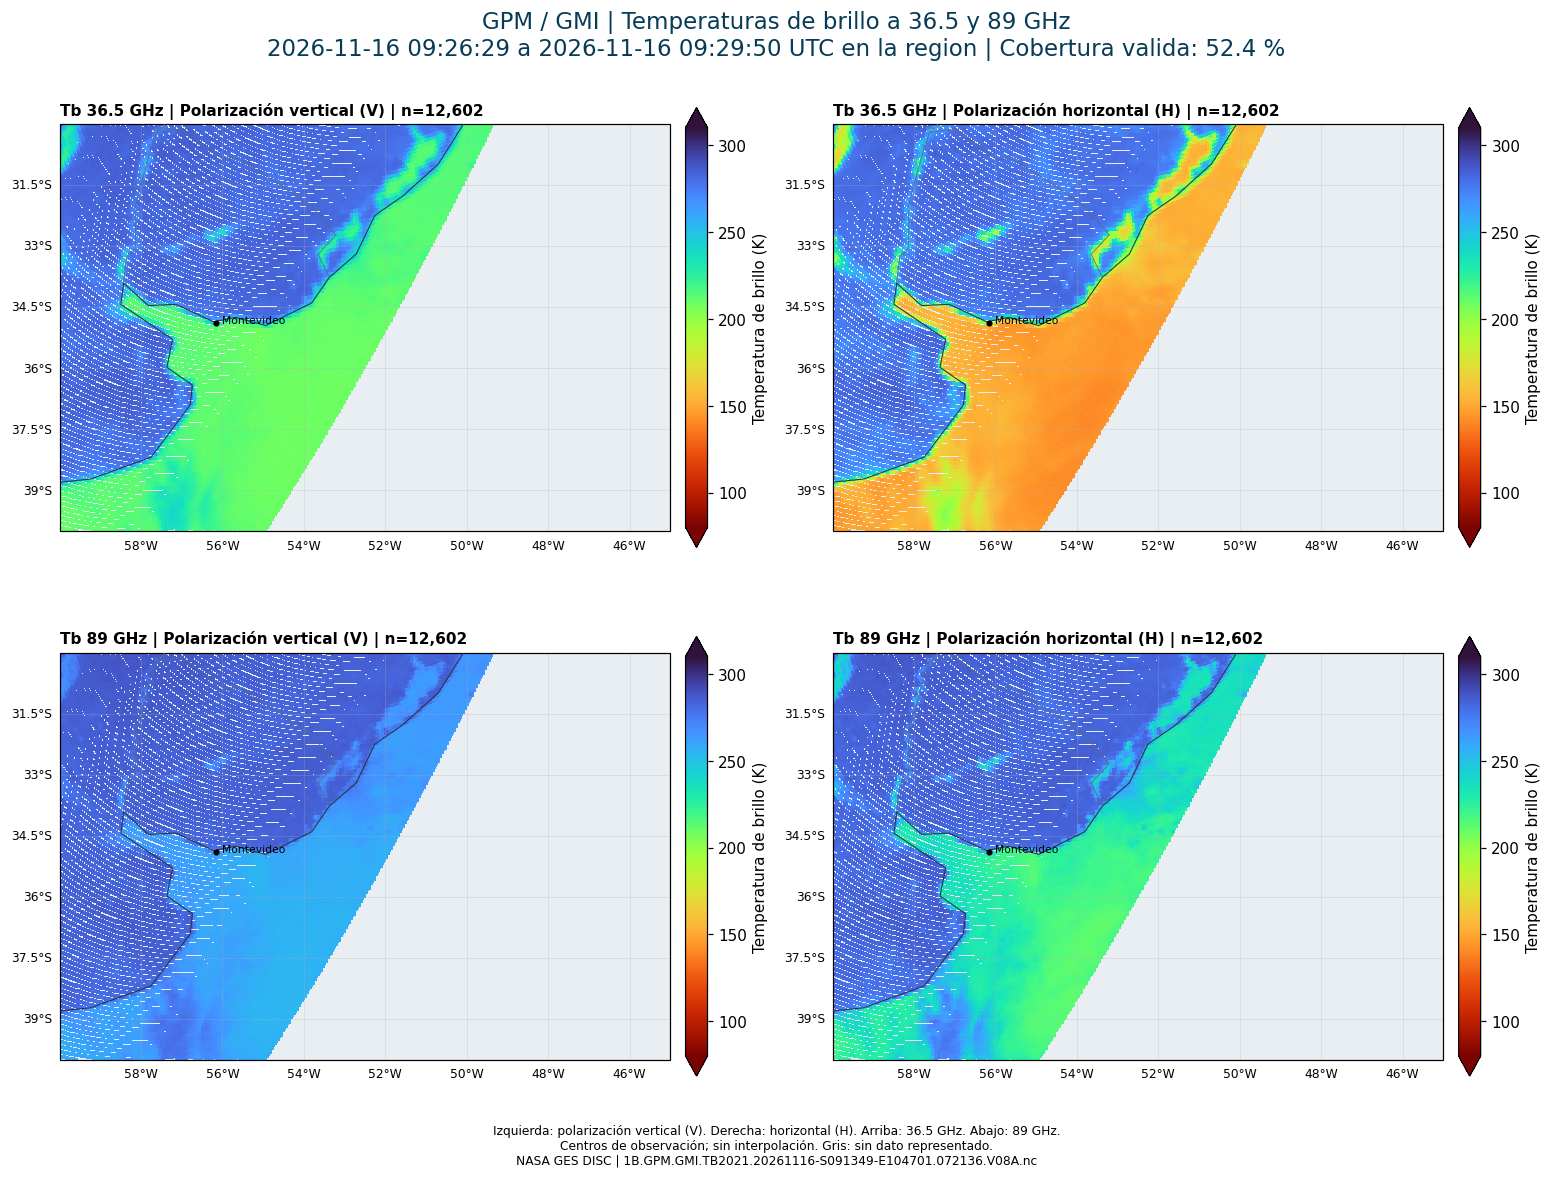

FIGURA 2: diferencia Tb(V) - Tb(H), en K. Izquierda: 37 GHz; derecha: 89 GHz. No es un cociente.


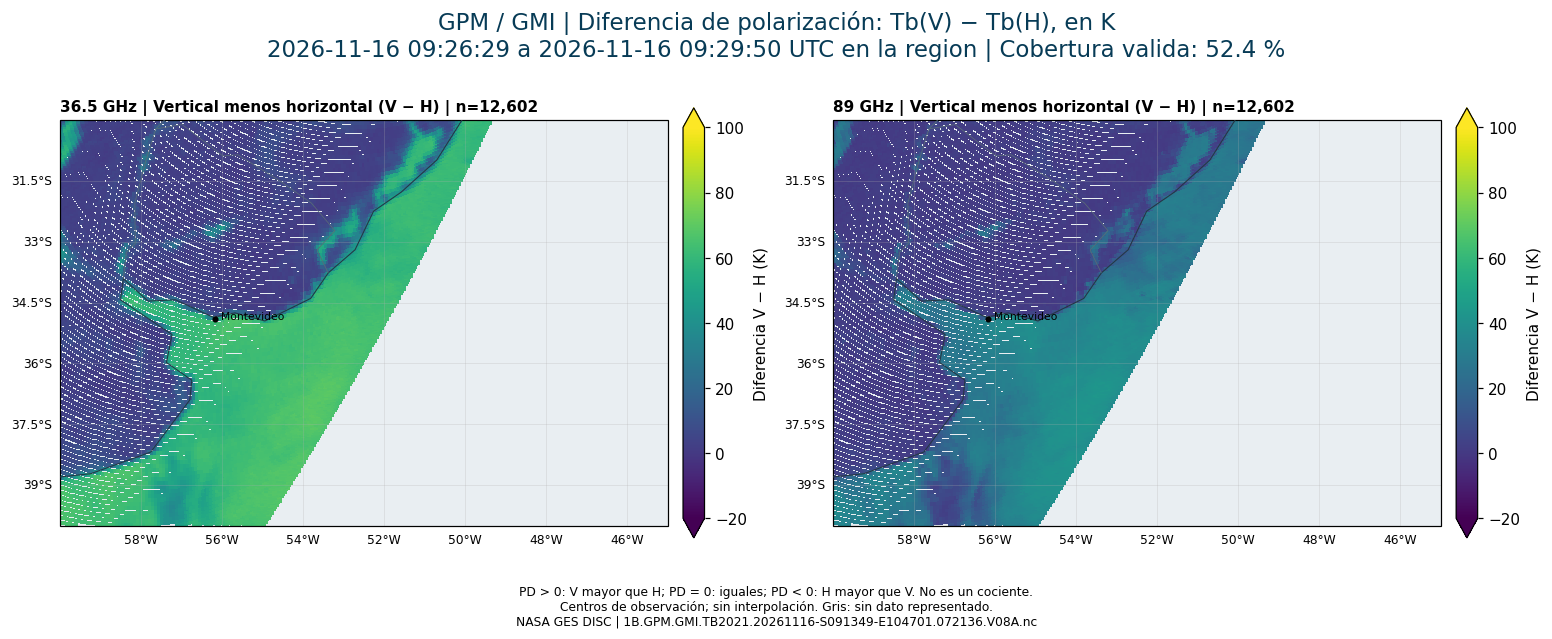

  0%|          | 0/1 [00:00<?, ?it/s]


Evaluando: 1B.GPM.GMI.TB2021.20261116-S074036-E091348.072135.V08A.nc
DESCARTADA: cobertura válida 0.01 % < 40 %.


,archivo,aceptada,estado,inicio_region_UTC,fin_region_UTC,centros_en_region_y_periodo,centros_con_algun_canal_valido,barridos_en_region_y_periodo,validos_37V,validos_37H,validos_89V,validos_89H,cobertura_geometrica_pct,cobertura_valida_pct,area_region_km2
0,1B.GPM.GMI.TB2021.20261117-S205753-E223105.072...,False,descartada_cobertura_baja,2026-11-17 22:16:05.933000+00:00,2026-11-17 22:18:00.307000+00:00,2835,2835,62,2835,2835,2835,2835,7.116759,7.116759,1.517190e+06
1,1B.GPM.GMI.TB2021.20261116-S231248-E004600.072...,False,descartada_cobertura_baja,2026-11-17 00:35:04.885000+00:00,2026-11-17 00:35:46.134000+00:00,268,268,23,268,268,268,268,0.456689,0.456689,1.517190e+06
2,1B.GPM.GMI.TB2021.20261116-S091349-E104701.072...,True,aceptada,2026-11-16 09:26:29.857000+00:00,2026-11-16 09:29:50.480000+00:00,12602,12602,108,12602,12602,12602,12602,52.412170,52.412170,1.517190e+06
3,1B.GPM.GMI.TB2021.20261116-S074036-E091348.072...,False,descartada_cobertura_baja,2026-11-16 07:51:43.047000+00:00,2026-11-16 07:51:52.422000+00:00,21,21,6,21,21,21,21,0.008780,0.008780,1.517190e+06


Pasadas aceptadas y exportadas: 1 | Candidatos evaluados: 4


In [11]:
map_context = None
map_prepared = False
reportes = []
proveniencia = []
salidas_netcdf = []
candidatos = archivos[:MAX_CANDIDATOS] if MODO == 'local' else seleccion.to_dict('records')
for candidate in candidatos:
    if len(salidas_netcdf) >= MAX_ARCHIVOS:
        break
    path = candidate if MODO == 'local' else obtener_archivo(candidate)
    if path is None:
        reportes.append({'archivo': candidate['archivo'], 'estado': 'error_descarga', 'aceptada': False})
        continue
    print('\nEvaluando:', path.name)
    ds = None
    report = {'archivo': path.name, 'aceptada': False}
    try:
        ds, info = read_gmi(path, BBOX, INICIO_UTC, FIN_UTC)
        report.update(info)
        proveniencia.append({'archivo': path.name, 'bytes': path.stat().st_size, 'sha256': file_sha256(path)})
        if ds is None:
            report.update(cobertura_geometrica_pct=0.0, cobertura_valida_pct=0.0)
            print('DESCARTADA: sin centros en la región y período.')
            continue
        coverage = regional_coverage(ds, BBOX)
        fraction = coverage['cobertura_valida_fraccion']
        report.update(cobertura_geometrica_pct=100*coverage['cobertura_geometrica_fraccion'],
                      cobertura_valida_pct=100*fraction, area_region_km2=coverage['area_region_km2'])
        ds.attrs.update(cobertura_geometrica_pct=report['cobertura_geometrica_pct'],
                        cobertura_valida_pct=report['cobertura_valida_pct'],
                        cobertura_minima_fraccion=COBERTURA_MINIMA,
                        coverage_method='Area de malla de centros consecutivos con 4 canales validos / area BBOX; LAEA; sin extrapolar bordes')
        if not meets_coverage(fraction, COBERTURA_MINIMA):
            report['estado'] = 'descartada_cobertura_baja'
            print(f'DESCARTADA: cobertura válida {100*fraction:.2f} % < {100*COBERTURA_MINIMA:.0f} %.')
            continue
        if not report['centros_con_algun_canal_valido']:
            report['estado'] = 'descartada_sin_datos_validos'
            continue
        report.update(estado='aceptada', aceptada=True)
        print(f'ACEPTADA: cobertura válida {100*fraction:.2f} %; mínimo {100*COBERTURA_MINIMA:.0f} %.')
        stamp = pd.Timestamp(ds.time.values.min()).strftime('%Y%m%dT%H%M%S')
        stem = f'{stamp}_{path.stem}'
        target = RUN_DIR / (stem + '_region.nc')
        if not map_prepared:
            map_context = prepare_maps(USAR_CARTOPY)
            map_prepared = True
        for differences, suffix in [(False, '_Tb.png'), (True, '_polarizacion.png')]:
            if differences:
                print('FIGURA 2: diferencia Tb(V) - Tb(H), en K. Izquierda: 37 GHz; derecha: 89 GHz. No es un cociente.')
            else:
                print('FIGURA 1: Tb en K. Izquierda: vertical; derecha: horizontal. Arriba: 37 GHz; abajo: 89 GHz.')
            fig = plot_gmi(ds, BBOX, map_context, differences, RUN_DIR / (stem + suffix))
            plt.show()
            plt.close(fig)
        write_subset(ds, target)
        salidas_netcdf.append(target)
    except Exception as exc:
        report.update(estado='error_procesamiento', aceptada=False, detalle=str(exc))
        print('No se pudo procesar:', str(exc))
    finally:
        if ds is not None:
            ds.close()
        reportes.append(report)

resumen = pd.DataFrame(reportes)
resumen.to_csv(RUN_DIR / 'resumen_pasadas.csv', index=False, encoding='utf-8-sig')
display(resumen)
print('Pasadas aceptadas y exportadas:', len(salidas_netcdf), '| Candidatos evaluados:', len(reportes))
if not salidas_netcdf:
    print(f'NINGUNA pasada evaluada cumple la cobertura válida mínima de {100*COBERTURA_MINIMA:.0f} % y los controles de calidad.')
    print('No se generan mapas ni subconjuntos. Revise el resumen y ajuste región, fechas o MAX_CANDIDATOS explícitamente.')

---

## 9 · Interpretar antigüedad y valores (5 min)

La edad se calcula respecto del momento de ejecución, usando **la última observación
válida en la región**, no el final global de la órbita. En modo caso un dato antiguo es
esperable; en modo reciente ayuda a detectar que el análisis no representa el estado actual.

El mínimo de $T_b$ es un descriptor de la muestra, no un estimador universal de intensidad
del ciclón. Tampoco promediamos distintos horarios como si fueran una imagen instantánea.


In [12]:
estadisticas = []
now_utc = pd.Timestamp.now(tz='UTC')
for path in salidas_netcdf:
    with xr.open_dataset(path) as ds:
        any_good = np.column_stack([ds['valid_' + k].values.astype(bool) for k in CHANNELS]).any(axis=1)
        if any_good.any():
            last = pd.Timestamp(ds.time.values[any_good].max()).tz_localize('UTC')
            age = (now_utc - last).total_seconds() / 3600
            local = last.tz_convert('America/Montevideo')
            print(ds.attrs['source_file'])
            print('Último barrido con algún canal válido:', last, '| Uruguay:', local)
            print(f'Antigüedad al ejecutar: {age:.1f} h. Modo de fechas: {VENTANA}.')
            if age > AVISO_ANTIGUEDAD_H:
                print('AVISO: supera el umbral configurado; no describirlo como una imagen actual.')
        for label in CHANNELS:
            values = ds['Tb_' + label].values
            values = values[np.isfinite(values)]
            if len(values):
                estadisticas.append({'archivo': ds.attrs['source_file'], 'canal': label,
                                     'n': len(values), 'min_K': float(values.min()),
                                     'p10_K': float(np.percentile(values, 10)),
                                     'mediana_K': float(np.median(values)), 'max_K': float(values.max())})
estadisticas = pd.DataFrame(estadisticas)
estadisticas.to_csv(RUN_DIR / 'estadisticas_canales.csv', index=False)
display(estadisticas)

1B.GPM.GMI.TB2021.20261116-S091349-E104701.072136.V08A.nc
Último barrido con algún canal válido: 2026-11-16 09:29:50.480000+00:00 | Uruguay: 2026-11-16 06:29:50.480000-03:00
Antigüedad al ejecutar: 98.6 h. Modo de fechas: caso.
AVISO: supera el umbral configurado; no describirlo como una imagen actual.


,archivo,canal,n,min_K,p10_K,mediana_K,max_K
0,1B.GPM.GMI.TB2021.20261116-S091349-E104701.072...,37V,12602,207.495438,209.514114,241.215347,286.720184
1,1B.GPM.GMI.TB2021.20261116-S091349-E104701.072...,37H,12602,139.229431,144.557602,200.875610,284.650085
2,1B.GPM.GMI.TB2021.20261116-S091349-E104701.072...,89V,12602,252.874527,255.934311,275.373657,288.847229
3,1B.GPM.GMI.TB2021.20261116-S091349-E104701.072...,89H,12602,211.391876,217.950531,262.567291,288.152557


---

## 10 · Guardar un registro reproducible

El manifiesto identifica producto, versión, caja, fechas, filtros, consulta, archivos,
errores, cobertura y versiones de paquetes. No guarda contraseñas ni tokens. El NetCDF de salida
es **un subconjunto derivado**; conserve los originales y cite el DOI de NASA.
En Colab descargue sus resultados antes de cerrar la sesión, porque el almacenamiento
de la sesión es temporal. La siguiente celda entrega enlaces y un ZIP de los resultados.


In [ ]:
manifest = {
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'product': PRODUCTO, 'version': VERSION, 'provider': PROVEEDOR,
    'doi': '10.5067/GPM/GMI/GPM/1B/08', 'mode': MODO, 'date_mode': VENTANA,
    'start_utc': INICIO_UTC, 'end_utc': FIN_UTC, 'bbox_west_south_east_north': BBOX,
    'catalog_search': CMR_URL if MODO == 'earthdata' else None,
    'selected_catalog_records': seleccion.to_dict('records') if not seleccion.empty else [],
    'source_files': proveniencia, 'download_errors': errores_descarga,
    'processing_report': reportes,
    'quality': 'dataQuality == 0; RFIFlag == 0 por frecuencia; Tb en [0,400] K; rellenos excluidos',
    'channels_zero_based': CHANNELS,
    'author': 'Dr. Marcial Garbanzo Salas',
    'minimum_coverage_fraction': COBERTURA_MINIMA,
    'coverage_method': 'Union de celdas entre centros consecutivos, 4 canales validos, area LAEA / area BBOX; sin extrapolar',
    'maximum_accepted_passes': MAX_ARCHIVOS, 'maximum_candidates': MAX_CANDIDATOS,
    'package_versions': {p: importlib.metadata.version(p) for p in ['numpy','pandas','requests','h5py','xarray','netCDF4','matplotlib','shapely','pyproj']}
}
# NaN de tamaños ausentes se convierte a null para obtener JSON estricto.
def json_clean(value):
    if isinstance(value, dict): return {k: json_clean(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)): return [json_clean(v) for v in value]
    if isinstance(value, (float, np.floating)) and not np.isfinite(value): return None
    if isinstance(value, np.generic): return value.item()
    return value
(RUN_DIR / 'manifest.json').write_text(json.dumps(json_clean(manifest), ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

import zipfile
zip_path = RUN_DIR.with_suffix('.zip')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for path in sorted(RUN_DIR.iterdir()):
        if path.is_file():
            z.write(path, arcname=path.name)
display(FileLink(str(zip_path)))
print('Resultados:', RUN_DIR.resolve())
print('El ZIP no incluye los originales orbitales, solo los resultados y la trazabilidad.')

---

## 11 · Actividades para el grupo

1. Identifique dos estructuras presentes a 37 y 89 GHz. ¿Qué hipótesis sobre agua líquida
   e hielo sugieren? ¿Qué otra observación necesita para contrastarlas?
2. Compare cobertura geométrica y válida en el resumen. Explique por qué se rechazó una pasada con menos del 40 %. Ubique el centro del sistema según el análisis meteorológico del curso. ¿Quedó dentro
   del barrido? Distinga **ausencia de observación**, **dato rechazado** y **Tb válida**.
3. Compare V y H sobre mar y continente. Explique por qué una diferencia de polarización
   no puede interpretarse igual sobre ambas superficies.
4. Repita para otra pasada, conservando la caja y escalas. Reporte el tiempo transcurrido
   antes de atribuir diferencias a evolución del sistema.
5. Combine el diagnóstico con GOES y ASCAT. Anote el desfase temporal y evite tratar
   observaciones separadas por horas como simultáneas.

**Entrega breve:** una figura con hora UTC, identificación del archivo, dos observaciones
físicas, una limitación de cobertura y una decisión sobre su utilidad para el análisis actual.

### Del ejercicio a un proceso repetible

Para repetir el análisis, cambie fechas y región y ejecute nuevamente. En un servicio
automatizado use credenciales administradas fuera del código, registre por separado
ausencia de granulos y errores de red, controle antigüedad y conserve los archivos ya
procesados. Este notebook **no crea una tarea programada** ni garantiza continuidad NRT.

### Si necesita ayuda

| Síntoma | Qué revisar |
|---|---|
| No aparecen granulos | Región, fechas, versión y publicación; no equivale a ausencia de lluvia |
| El granulo aparece pero no produce figura | Puede no tener centros en la caja/período o no alcanzar 40 % de cobertura válida; revise el resumen |
| Error 401/403 | Earthdata Login y autorización de GES DISC; no usar datos de acceso PPS/EUMETSAT |
| El archivo no es HDF5/NetCDF4 | Posible página HTML de autenticación o descarga incompleta |
| Faltan `S1/Tb` o indicadores | Archivo de otro producto o subconjunto con estructura distinta; usar original L1B V08 |
| Todos los puntos quedan rechazados | Examinar `dataQuality`, RFI y rellenos; no quitar controles para forzar una figura |
| Fallan las costas | `USAR_CARTOPY=False` conserva los datos en ejes lon/lat; preparar la caché antes de clase |
| Instalación falla en Python de 32 bits | Usar Colab o Anaconda de 64 bits; este notebook no declara compatibilidad de 32 bits |
| No se puede acceder a NASA desde el aula | Descargar previamente los originales y usar `MODO='local'` |

### Fuentes y documentación

- [JMA: análisis de ciclones mediante microondas; polarización e interpretación física](https://www.jma.go.jp/jma/jma-eng/jma-center/rsmc-hp-pub-eg/techrev/text10-3.pdf).
- [CIRA/RAMMB: interpretación de imágenes pasivas de 37 y 89 GHz](https://tc.cira.colostate.edu/tc_realtime/about.asp).
- [Cecil y Chronis (2018): diferencias de polarización y temperaturas corregidas (PCT)](https://doi.org/10.1175/JAMC-D-18-0022.1).
- [Gong y Wu (2017): microfísica del hielo y diferencias V–H medidas por GMI](https://pmc.ncbi.nlm.nih.gov/articles/PMC7402201/).

- [GPM GMI L1B V08: ficha y DOI](https://doi.org/10.5067/GPM/GMI/GPM/1B/08).
- [Notas V08: NetCDF4, misma estructura V07 y geolocalización revisada](https://pps.gsfc.nasa.gov/Documents/GMI_L1B_V08_Release_Notes.pdf).
- [Especificación GPM V7.16, sección 5.17, páginas impresas 811–858](https://gpm.nasa.gov/sites/default/files/2024-06/filespec.GPM_.pdf).
- [NOAA: frecuencias y polarizaciones de GMI](https://www.star.nesdis.noaa.gov/mirs/gpmgmi.php).
- [NASA SPoRT: interpretación de microondas](https://weather.ndc.nasa.gov/sport/passiveMicrowave/).
- [NASA CMR: API de búsqueda](https://cmr.earthdata.nasa.gov/search/site/docs/search/api.html).
- [earthaccess: API de autenticación y descarga](https://earthaccess.readthedocs.io/en/latest/api/).

Material didáctico de análisis de observaciones; no constituye un aviso meteorológico oficial.
